# Práctica corta — Representación de un espacio de búsqueda
## Fundamentos de Inteligencia Artificial

### Objetivo
Representar en Python un problema sencillo como un grafo, identificando:

- estados;
- conexiones;
- estado inicial;
- estado meta.

> En esta práctica **todavía no utilizaremos BFS ni DFS**. El objetivo es comprender cómo se representa un espacio de búsqueda en Python.


## Problema base

Un robot se mueve dentro de un pequeño centro de trabajo con las siguientes zonas:

- Entrada
- Recepción
- Oficina
- Laboratorio
- Almacén
- Salida

Las conexiones permitidas son:

- Entrada ↔ Recepción
- Recepción ↔ Oficina
- Recepción ↔ Laboratorio
- Oficina ↔ Almacén
- Laboratorio ↔ Almacén
- Almacén ↔ Salida

**Estado inicial:** Entrada  
**Estado meta:** Salida


## Parte 1 — Representación del espacio

Antes de ejecutar el programa, responde:

1. ¿Cuántos estados existen?
2. ¿Cuántas conexiones existen?
3. ¿Cuál es el estado inicial?
4. ¿Cuál es la meta?
5. ¿Existe más de un camino entre Entrada y Salida?

Escribe tus respuestas aquí:

- Estados:
- Conexiones:
- Inicio:
- Meta:
- ¿Más de un camino?:


In [1]:
import networkx as nx
import matplotlib.pyplot as plt


## Parte 2 — Definir el espacio de búsqueda

En el diccionario `grafo`, cada estado tiene una lista con los estados a los que puede desplazarse directamente.

Por ejemplo:

```python
"Recepción": ["Entrada", "Oficina", "Laboratorio"]
```

significa:

> Desde Recepción se puede ir directamente a Entrada, Oficina o Laboratorio.


In [2]:
grafo = {
    "Entrada": ["Recepción"],
    "Recepción": ["Entrada", "Oficina", "Laboratorio"],
    "Oficina": ["Recepción", "Almacén"],
    "Laboratorio": ["Recepción", "Almacén"],
    "Almacén": ["Oficina", "Laboratorio", "Salida"],
    "Salida": ["Almacén"]
}

inicio = "Entrada"
meta = "Salida"

print("Estado inicial:", inicio)
print("Estado meta:", meta)
print("Estados:", list(grafo.keys()))


Estado inicial: Entrada
Estado meta: Salida
Estados: ['Entrada', 'Recepción', 'Oficina', 'Laboratorio', 'Almacén', 'Salida']


## Parte 3 — Dibujar el espacio de búsqueda

Ejecuta la siguiente celda y compara el resultado con el dibujo que hiciste manualmente.


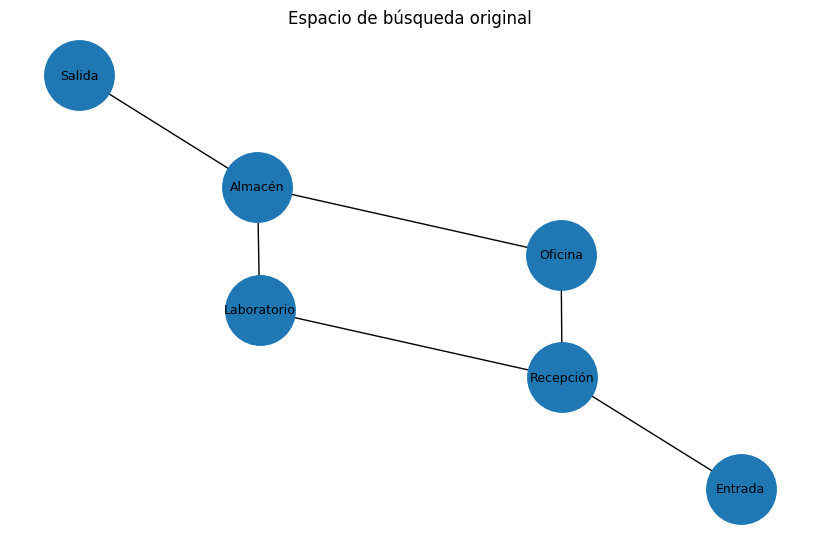

In [3]:
G = nx.Graph()

for estado, vecinos in grafo.items():
    for vecino in vecinos:
        G.add_edge(estado, vecino)

plt.figure(figsize=(8, 5))
nx.draw(G, with_labels=True, node_size=2500, font_size=9)
plt.title("Espacio de búsqueda original")
plt.show()


## Parte 4 — Primera modificación obligatoria

Ahora debes modificar el problema:

1. Agrega una nueva zona llamada **Cafetería**.
2. Conecta Cafetería con **Oficina**.
3. Conecta Cafetería con **Salida**.
4. Cambia la meta de `Salida` a `Cafetería`.

Modifica el código de la siguiente celda.


In [4]:
import networkx as nx
import matplotlib.pyplot as plt


In [5]:
grafo = {
    "Entrada": ["Recepción"],
    "Recepción": ["Entrada", "Oficina", "Laboratorio"],
    "Oficina": ["Recepción", "Almacén", "Cafetería"],
    "Cafetería": ["Oficina", "Salida"],
    "Laboratorio": ["Recepción", "Almacén"],
    "Almacén": ["Oficina", "Laboratorio", "Salida"],
    "Salida": ["Almacén"],

}

inicio = "Entrada"
meta = "Cafetería"

print("Estado inicial:", inicio)
print("Estado meta:", meta)
print("Estados:", list(grafo.keys()))


Estado inicial: Entrada
Estado meta: Cafetería
Estados: ['Entrada', 'Recepción', 'Oficina', 'Cafetería', 'Laboratorio', 'Almacén', 'Salida']


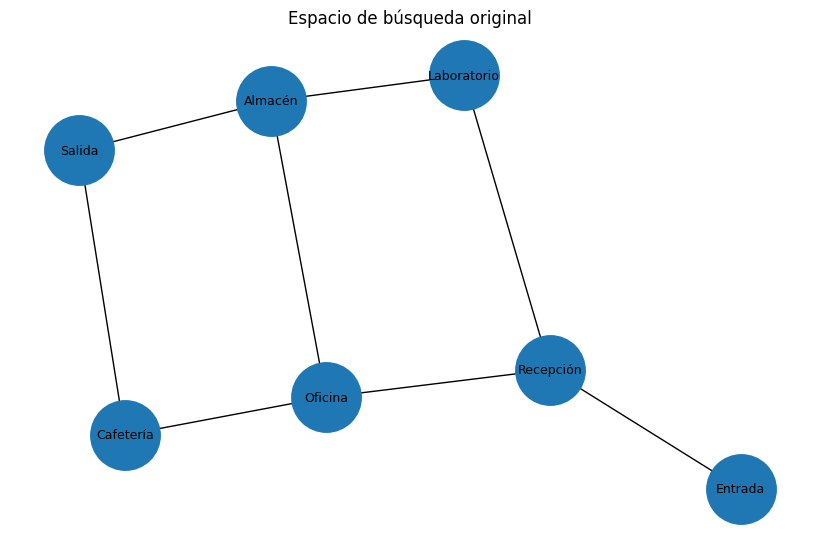

In [6]:
G = nx.Graph()

for estado, vecinos in grafo.items():
    for vecino in vecinos:
        G.add_edge(estado, vecino)

plt.figure(figsize=(8, 5))
nx.draw(G, with_labels=True, node_size=2500, font_size=9)
plt.title("Espacio de búsqueda original")
plt.show()


## Parte 5 — Visualizar el problema modificado

Si la modificación fue correcta, la nueva zona debe aparecer en el grafo.


### Preguntas

1. ¿Cuántos estados existen ahora? 7
2. ¿Cuántas conexiones agregaste? 2
3. ¿Qué cambió visualmente en el espacio de búsqueda? Se agrego  otro nodo y 2 conexiones
4. ¿Existe un camino desde Entrada hasta Cafetería?

Escribe tus respuestas aquí:si, entrada,receo,ofi,cafe

...


## Parte 6 — Segunda modificación obligatoria

Supongamos que el **Laboratorio queda temporalmente cerrado**.

Modifica el grafo para que:

- Laboratorio ya no tenga conexiones.
- Ningún otro estado tenga conexión hacia Laboratorio.

Después vuelve a visualizar el espacio.


### Preguntas de análisis

1. ¿Laboratorio sigue apareciendo como estado? Si
2. ¿Tiene conexiones? no
3. ¿Sigue existiendo un camino entre Entrada y Salida?si
4. ¿Qué diferencia hay entre dejar Laboratorio como estado sin conexiones y eliminarlo completamente del diccionario?Pues dejarlo como estado sigue ocupando un nodo,eliminarlo completamente seria quitarlo del todo y ya no seria un estado
5. ¿Cuál de las dos opciones representa mejor que el Laboratorio está cerrado temporalmente? dejarlo sin conexiones

Escribe tus respuestas aquí:

...


In [7]:
grafo = {
    "Entrada": ["Recepción"],
    "Recepción": ["Entrada", "Oficina"],
    "Oficina": ["Recepción", "Almacén", "Cafetería"],
    "Cafetería": ["Oficina", "Salida"],
    "Laboratorio": [],
    "Almacén": ["Oficina", "Salida"],
    "Salida": ["Almacén", "Cafetería"],
}

inicio = "Entrada"
meta = "Cafetería"

print("Estado inicial:", inicio)
print("Estado meta:", meta)
print("Estados:", list(grafo.keys()))


Estado inicial: Entrada
Estado meta: Cafetería
Estados: ['Entrada', 'Recepción', 'Oficina', 'Cafetería', 'Laboratorio', 'Almacén', 'Salida']


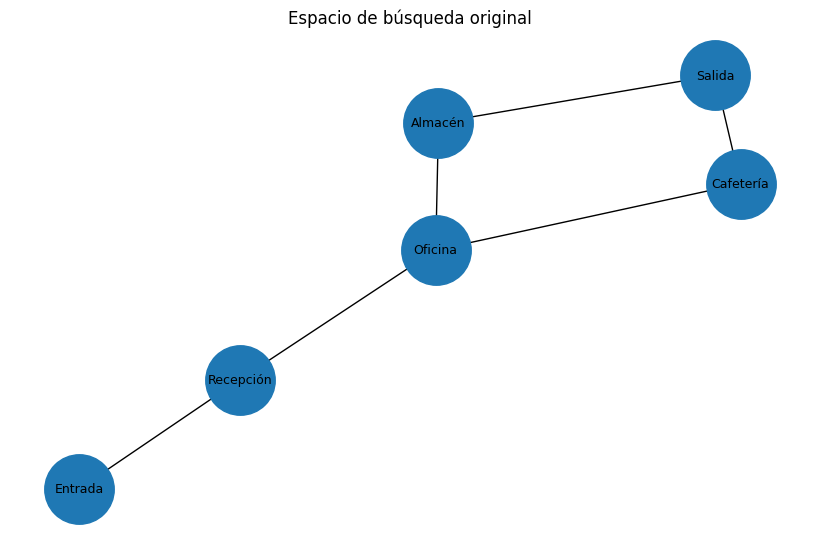

In [8]:
G = nx.Graph()

for estado, vecinos in grafo.items():
    for vecino in vecinos:
        G.add_edge(estado, vecino)

plt.figure(figsize=(8, 5))
nx.draw(G, with_labels=True, node_size=2500, font_size=9)
plt.title("Espacio de búsqueda original")
plt.show()


## Parte 7 — Reto opcional

Realiza una modificación adicional:

- agrega una nueva zona;
- elimina una conexión;
- cambia el estado inicial;
- cambia la meta.

Después vuelve a dibujar el espacio de búsqueda.

Describe qué cambiaste:

...


# Conclusión

Responde en 3 a 5 líneas:

- ¿Qué representa un nodo?
- ¿Qué representa una conexión?
- ¿Qué sucede con el espacio de búsqueda cuando modificamos el problema?

### Idea central

**El espacio de búsqueda cambia cuando cambian los estados o las transiciones posibles del problema.**

Un nodo representa un estado o ubicación posible del entorno como las distintas zonas del centro de trabajo), mientras que una conexión representa una transición o acción válida para moverse directamente de un estado a otro. Al modificar el problema (añadiendo/eliminando zonas o accesos), el espacio de búsqueda se altera en su tamaño, alcance o estructura, lo que cambia las rutas disponibles y la complejidad para llegar del estado inicial a la meta.

Un nodo lo definimos como una ubicacion posible, mientras que una conexion representa una transicion para moverse entre un estado y otro, al modificar el problema, el espacio de busqueda se altera en tamano, el alcance, la estructura, lo que cambia son las rutas disponibles para trasladarse dentro del espacio de busqueda.
Hanniel Olvera Mata
Fernando Jimenez Angeles
